In [1]:
from pathlib import Path

import SimpleITK as sitk
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Configurations and Tools

In [2]:
csv_path = "/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/pipeline_checkpoints.csv"
manifest_path = "/Users/furkan/projects/mebar-radiology/data/manifest.csv"

In [3]:
from IPython.display import display, HTML


# render a dataframe fully (no pandas ellipsis) inside a scrollable container
def show_scrollable(df, max_height="300px"):
    display(HTML(f'<div style="max-height:{max_height}; overflow:auto; border:1px solid #999">{df.to_html()}</div>'))

# Exploration

In [4]:
manifest_df = pd.read_csv(manifest_path)
csv_df = pd.read_csv(csv_path)

In [5]:
# only ADC samples matter for the negative-voxel fix
project_root = Path(manifest_path).resolve().parent.parent

adc_manifest_df = manifest_df[manifest_df["modality"] == "ADC"].reset_index(drop=True)
adc_manifest_df["image_path"] = adc_manifest_df["image_path"].map(lambda p: str(project_root / p))

adc_csv_df = csv_df[csv_df["modality"] == "ADC"].reset_index(drop=True)

## Negative voxels

In [6]:
# every negative voxel is counted straight from the written image, no geometry involved
def negative_voxel_stats(df, path_col="image_out_path"):
    rows = []
    negative_rows = []
    for sample_id, image_path in zip(df["sample_id"], df[path_col]):
        array = sitk.GetArrayFromImage(sitk.ReadImage(image_path)).astype(np.float64)
        negative = array < 0
        n_negative = int(negative.sum())
        rows.append(
            {
                "sample_id": sample_id,
                "voxel_count": int(array.size),
                "negative_count": n_negative,
                "negative_ratio": float(negative.mean()),
                "min": float(array.min()),
                "max": float(array.max()),
                "mean": float(array.mean()),
            }
        )
        if n_negative > 0:
            negative_rows.append((sample_id, Path(image_path).name))

    for sample_id, file_name in negative_rows:
        print(f"{sample_id}  {file_name}")

    return pd.DataFrame(rows)

In [7]:
neg_stats_df = negative_voxel_stats(adc_manifest_df, path_col="image_path")
show_scrollable(neg_stats_df)
neg_stats_df.describe()

6da62ba89f121b65  CELIK OSMAN.Seq8.Ser602.Img1.nrrd
9209fbda98cda373  KOZIK TUNCAY.Seq38.Ser950.Img1.nrrd
003da9c17d67938b  MERDIM BURHAN.Seq16.Ser602.Img1.nrrd
f2ee2155e8541645  TASIMOVA GULBARSHIN.Seq13.Ser1102.Img1.nrrd
34457c052fa53b67  TUZ GULSEN.Seq22.Ser1302.Img1.nrrd
8b579d8c7a2c7cd9  ANDELKOVIC GORAN.Seq23.Ser1450.Img1.nrrd
9e594f345c74fecc  OZYURT ASIYE.Seq50.Ser2802.Img1.nrrd
9672ecc7488b9389  RACHEV NIKOLAY.Seq17.Ser1202.Img1.nrrd
c59b42edffd18083  SIS CEMAL.Seq30.Ser1902.Img1.nrrd
d27b47b4999b753a  AKBAS EMINE MELEK.Seq15.Ser800.Img1.nrrd
9d5fc7c15d1bd36e  GOK KADRIYE.Seq55.Ser3002.Img1.nrrd
4ac9f924489ebdcc  SAFAROVA ILAHA.Seq19.Ser1402.Img1.nrrd
3c4e73d29e28261b  35242480.nrrd
b64f472cfa245fb4  RASHIDOV BAKHITZHAN.Seq7.Ser502.Img1.nrrd
851ed2eba5a2c7be  YETIMLER REMZIYE.Seq12.Ser1002.Img1.nrrd
a77fe0fb06a7f625  CALISKAN OZALP BAHAR.Seq16.Ser1102.Img1.nrrd
7e1a3b81d54dcd99  OBI NDIBE JOSEPHAT.Seq27.Ser1702.Img1.nrrd
411d55c74cb228ab  ALIYEV HASAN.Seq24.Ser1502.Img1.nrrd
c

,sample_id,voxel_count,negative_count,negative_ratio,min,max,mean
0,0d6f73a01539ae0d,2257920,0,0.000000,0.000000,3366.000000,274.265785
1,c5574c732708c9c0,655360,0,0.000000,0.000000,3258.000000,878.815263
2,85e3e9f712fe9029,1806336,0,0.000000,0.000000,3540.000000,291.570456
3,6d382c4f0f97ffa6,756400,0,0.000000,0.000000,3855.000000,1121.340985
4,c650692054c62b07,1806336,0,0.000000,0.000000,3286.000000,289.188864
5,ca2f17811a30d3a5,907680,0,0.000000,0.000000,3847.000000,555.176747
6,3280ab13a3838901,2949120,0,0.000000,0.000000,4095.000000,414.653832
7,6da62ba89f121b65,787968,155870,0.197813,-0.432499,1.818855,0.862208
8,11adf6fc33900eb7,619520,0,0.000000,0.000000,4095.000000,762.936554
9,988742e3c62af03c,819200,0,0.000000,0.000000,3139.000000,523.415166


,voxel_count,negative_count,negative_ratio,min,max,mean
count,1.880000e+02,1.880000e+02,188.000000,188.000000,188.000000,188.000000
mean,1.493584e+06,5.189308e+04,0.032477,-2.806545,3425.178361,491.401367
std,8.224902e+05,2.129958e+05,0.100136,26.326348,1343.222345,293.620468
min,2.580480e+05,0.000000e+00,0.000000,-256.000000,1.623679,0.187293
25%,8.192000e+05,0.000000e+00,0.000000,0.000000,3435.750000,291.362311
50%,1.310720e+06,0.000000e+00,0.000000,0.000000,4085.000000,486.572915
75%,2.007040e+06,0.000000e+00,0.000000,0.000000,4095.000000,694.383446
max,5.068800e+06,1.315232e+06,0.689176,0.000000,9042.000000,1616.552750


In [8]:
n_negative = int((neg_stats_df["negative_count"] > 0).sum())
print(f"samples with negative voxels: {n_negative} / {len(neg_stats_df)}")

samples with negative voxels: 25 / 188


In [9]:
# one histogram per numeric column of the result, 3 per row
def visualize_numeric_features(df):
    numeric_cols = [col for col in df.columns if col not in {"sample_id", "voxel_count", "mean", "max"} and df[col].dtype != object]

    grid_cols = 3
    grid_rows = int(np.ceil(len(numeric_cols) / grid_cols))
    fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(15, 4 * grid_rows))
    axes = np.atleast_1d(axes).reshape(grid_rows, grid_cols)

    for ax, col in zip(axes.flat, numeric_cols):
        ax.hist(df[col], bins=30)
        ax.set_title(col)

    for ax in axes.flat[len(numeric_cols):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()

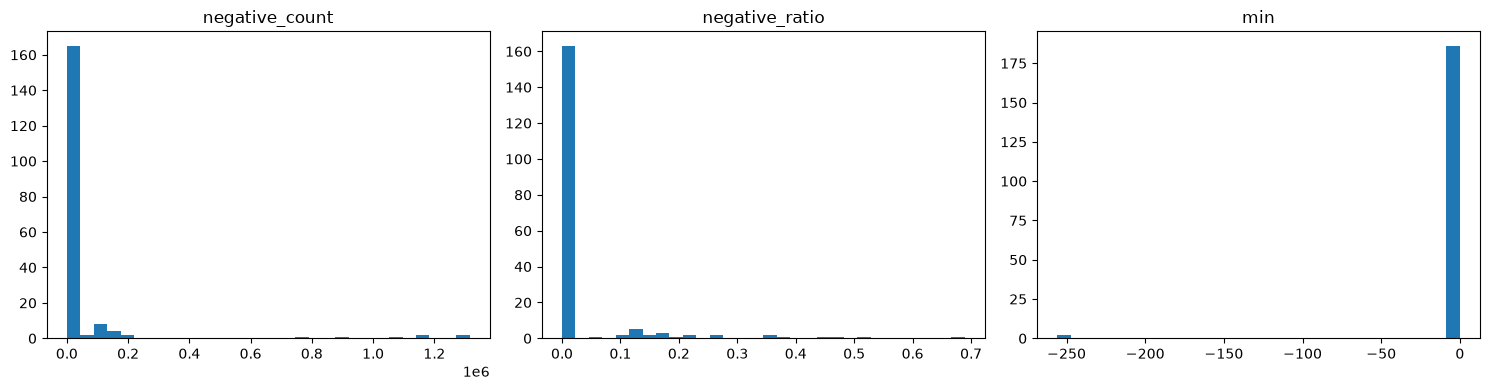

In [10]:
visualize_numeric_features(neg_stats_df)

## Checkpoint CSV (after neg_fix)

In [11]:
csv_neg_stats_df = negative_voxel_stats(adc_csv_df)
show_scrollable(csv_neg_stats_df)
csv_neg_stats_df.describe()

,sample_id,voxel_count,negative_count,negative_ratio,min,max,mean
0,0d6f73a01539ae0d,2257920,0,0.0,0.0,3366.000000,274.265785
1,c5574c732708c9c0,655360,0,0.0,0.0,3258.000000,878.815263
2,85e3e9f712fe9029,1806336,0,0.0,0.0,3540.000000,291.570456
3,6d382c4f0f97ffa6,756400,0,0.0,0.0,3855.000000,1121.340985
4,c650692054c62b07,1806336,0,0.0,0.0,3286.000000,289.188864
5,ca2f17811a30d3a5,907680,0,0.0,0.0,3847.000000,555.176747
6,3280ab13a3838901,2949120,0,0.0,0.0,4095.000000,414.653832
7,6da62ba89f121b65,787968,0,0.0,0.0,1.818855,0.866732
8,11adf6fc33900eb7,619520,0,0.0,0.0,4095.000000,762.936554
9,988742e3c62af03c,819200,0,0.0,0.0,3139.000000,523.415166


,voxel_count,negative_count,negative_ratio,min,max,mean
count,1.870000e+02,187.0,187.0,187.0,187.000000,187.000000
mean,1.490791e+06,0.0,0.0,0.0,3421.596427,491.355358
std,8.238033e+05,0.0,0.0,0.0,1345.927733,292.809155
min,2.580480e+05,0.0,0.0,0.0,1.623679,0.187293
25%,8.192000e+05,0.0,0.0,0.0,3433.500000,294.760325
50%,1.310720e+06,0.0,0.0,0.0,4076.000000,486.389004
75%,1.981952e+06,0.0,0.0,0.0,4095.000000,692.471817
max,5.068800e+06,0.0,0.0,0.0,9042.000000,1616.552750


In [12]:
csv_n_negative = int((csv_neg_stats_df["negative_count"] > 0).sum())
print(f"samples with negative voxels (after neg_fix): {csv_n_negative} / {len(csv_neg_stats_df)}")

samples with negative voxels (after neg_fix): 0 / 187


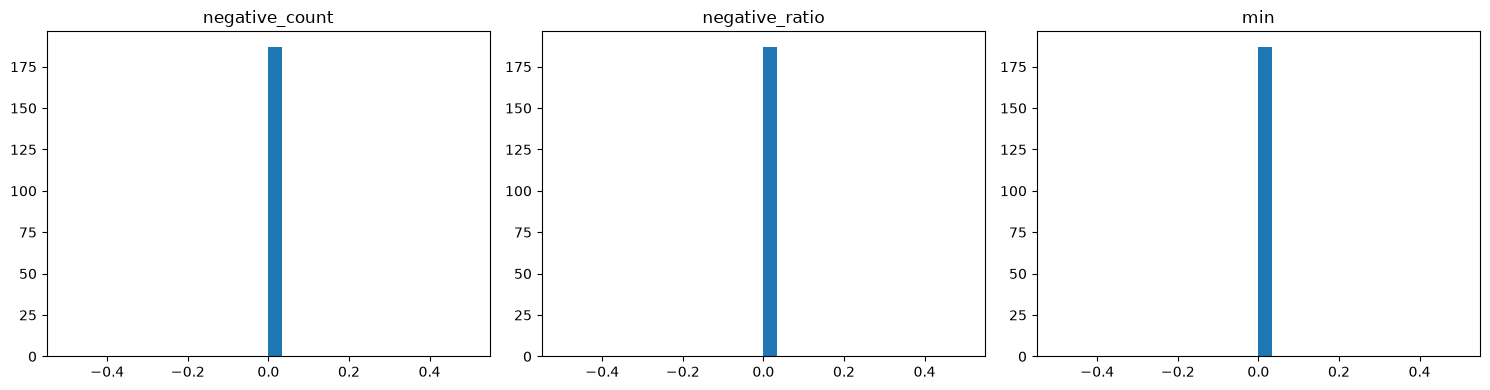

In [13]:
visualize_numeric_features(csv_neg_stats_df)